# FitBot 4B – Fine-tuning Qwen3-4B-Instruct-2507 with QLoRA (college GPU PC)

Fine-tunes **`Qwen/Qwen3-4B-Instruct-2507`** (4.0 B parameters, Apache-2.0) on **FitBot dataset v2**
(5,470 conversations: 4,382 train / 527 validation / 561 test, built from 871 exercises, USDA foods and
hand-written fitness topics) with **QLoRA** (4-bit base model + LoRA adapters), evaluates the **base vs
fine-tuned** model, compares with the current FitBot 360M model on the original v1 test questions, and saves
the adapter (+ optional merged model) for the FitBot app.

**Target machine:** NVIDIA RTX 4070 (12 GB) · 32 GB RAM · Windows 10/11 (native or WSL2) or Linux.
See `COLLEGE_PC_GUIDE.md` for setup. **Run the smoke test first (Section 0), then the full run.**

| Section | What happens | Typical time on RTX 4070 |
|---|---|---|
| 0 | Choose SMOKE (2-3 min check) or FULL run | – |
| 1-2 | Check libraries + GPU | 1 min |
| 3-4 | Config, load dataset | 1 min |
| 5 | Download (first time, ~8 GB) + load model in 4-bit | 5-15 min first time, 1-2 min after |
| 6 | Tokenize | 1 min |
| 7 | Baseline evaluation of the base model | 10-20 min |
| 8-9 | LoRA + training (2 epochs, auto-resume) | ~40-100 min |
| 10-11 | Loss curves, fine-tuned evaluation, comparison | 10-20 min |
| 12-13 | Save adapter (+ optional merged 16-bit model), package | 5-15 min |

Everything is saved under `outputs/` next to this notebook, so if the session ends you can simply run all
cells again - training **resumes from the last checkpoint**.

## 0. Run mode

In [1]:
import os
# "1" = smoke test (tiny subset, a few steps; verifies the whole pipeline in a few minutes)
# "0" = full fine-tuning run
os.environ.setdefault("FITBOT_SMOKE", "1")
# Only if you get "CUDA out of memory": uncomment, then Kernel > Restart & Run All (training resumes)
# os.environ["FITBOT_BATCH"] = "1"        # micro-batch per step (effective batch stays 16)
# os.environ["FITBOT_MAX_LEN"] = "1024"   # max tokens per example
SMOKE = os.environ["FITBOT_SMOKE"] == "1"
print("SMOKE TEST" if SMOKE else "FULL RUN")

FULL RUN


## 1. Libraries

In [2]:
import sys, json, time, math, random, re, gc, zipfile, platform
from pathlib import Path
import importlib

need = ["torch", "transformers", "peft", "accelerate", "datasets", "rouge_score", "matplotlib"]
missing = [m for m in need if importlib.util.find_spec(m) is None]
if missing:
    raise SystemExit(f"Missing packages: {missing}. Install them first - see COLLEGE_PC_GUIDE.md")
import numpy as np, torch, transformers, peft, datasets
print("python", sys.version.split()[0], "|", platform.system(), "| torch", torch.__version__,
      "| transformers", transformers.__version__, "| peft", peft.__version__)
from packaging.version import Version
assert Version(transformers.__version__) >= Version("4.51.0"), "Qwen3 needs transformers >= 4.51"
HAS_BNB = importlib.util.find_spec("bitsandbytes") is not None
print("bitsandbytes available:", HAS_BNB)

W1009 12:15:57.482000 20776 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


python 3.12.10 | Windows | torch 2.11.0+cu128 | transformers 5.19.0 | peft 0.21.2
bitsandbytes available: True


## 2. GPU check

The notebook picks precision and batch size from the GPU. RTX 40xx (Ada) supports **bf16**.

In [3]:
if torch.cuda.is_available():
    DEVICE = "cuda"
    props = torch.cuda.get_device_properties(0)
    GPU_NAME, GPU_MEM_GB = props.name, props.total_memory / 1024**3
    USE_BF16 = torch.cuda.is_bf16_supported()
    USE_FP16 = not USE_BF16
    print(f"GPU: {GPU_NAME} | {GPU_MEM_GB:.1f} GB | CUDA {torch.version.cuda} | bf16={USE_BF16}")
elif torch.backends.mps.is_available():
    DEVICE, GPU_NAME, GPU_MEM_GB, USE_BF16, USE_FP16 = "mps", "Apple MPS", 0.0, False, False
else:
    DEVICE, GPU_NAME, GPU_MEM_GB, USE_BF16, USE_FP16 = "cpu", "none", 0.0, False, False
if DEVICE != "cuda" and not SMOKE:
    raise SystemExit("No NVIDIA GPU detected - check the driver / CUDA build of PyTorch (COLLEGE_PC_GUIDE.md).")
LOAD_4BIT = DEVICE == "cuda" and HAS_BNB
if DEVICE == "cuda" and not HAS_BNB:
    raise SystemExit("bitsandbytes is required for 4-bit loading on the GPU: pip install bitsandbytes")
# micro-batch from memory; gradient accumulation keeps the effective batch at 16
PER_DEVICE_BS = 4 if GPU_MEM_GB >= 22 else 2
if DEVICE != "cuda":
    PER_DEVICE_BS = 2
PER_DEVICE_BS = int(os.environ.get("FITBOT_BATCH", PER_DEVICE_BS))
GRAD_ACCUM = 16 // PER_DEVICE_BS
print(f"device={DEVICE} 4-bit={LOAD_4BIT} batch={PER_DEVICE_BS} x accum {GRAD_ACCUM} (effective 16)")

GPU: NVIDIA GeForce RTX 4070 | 12.0 GB | CUDA 12.8 | bf16=True
device=cuda 4-bit=True batch=2 x accum 8 (effective 16)


## 3. Configuration

In [4]:
CONFIG = {
    "base_model": os.environ.get("FITBOT_BASE_MODEL", "Qwen/Qwen3-4B-Instruct-2507"),
    "max_seq_length": int(os.environ.get("FITBOT_MAX_LEN", 1280)),           # longest v2 example is ~1,220 Qwen tokens
    "num_train_epochs": 2,            # 5.4k examples: 2 epochs is enough for a 4B model; early stopping guards
    "learning_rate": 1e-4,
    "lr_scheduler_type": "cosine",
    "warmup_ratio": 0.03,
    "weight_decay": 0.0,
    "per_device_train_batch_size": PER_DEVICE_BS,
    "gradient_accumulation_steps": GRAD_ACCUM,
    "lora_r": 16, "lora_alpha": 32, "lora_dropout": 0.05,
    "lora_target_modules": ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    "load_in_4bit": LOAD_4BIT, "quant_type": "nf4", "double_quant": True,
    "early_stopping_patience": 3,
    "seed": 42,
    "gen_max_new_tokens": 220,
    "gen_eval_new_test": 80,          # new-v2 test records used for generation metrics (+ all 97 v1 test records)
    "precision": "bf16" if USE_BF16 else ("fp16" if USE_FP16 else "fp32"),
    "device": DEVICE, "gpu_name": GPU_NAME,
}
if SMOKE:
    CONFIG.update({"max_steps": 4, "gen_max_new_tokens": 24, "gen_eval_new_test": 4, "max_seq_length": 768})
RUN_NAME = "fitbot-qwen3-4b-qlora" + ("-smoke" if SMOKE else "")
MERGE_FULL_MODEL = os.environ.get("FITBOT_MERGE", "1") == "1" and not SMOKE   # merged 16-bit copy (~8 GB)
random.seed(CONFIG["seed"]); np.random.seed(CONFIG["seed"]); torch.manual_seed(CONFIG["seed"])
print(json.dumps(CONFIG, indent=2))

{
  "base_model": "FitBot\\models\\base\\Qwen3-4B-Instruct-2507",
  "max_seq_length": 1280,
  "num_train_epochs": 2,
  "learning_rate": 0.0001,
  "lr_scheduler_type": "cosine",
  "warmup_ratio": 0.03,
  "weight_decay": 0.0,
  "per_device_train_batch_size": 2,
  "gradient_accumulation_steps": 8,
  "lora_r": 16,
  "lora_alpha": 32,
  "lora_dropout": 0.05,
  "lora_target_modules": [
    "q_proj",
    "k_proj",
    "v_proj",
    "o_proj",
    "gate_proj",
    "up_proj",
    "down_proj"
  ],
  "load_in_4bit": true,
  "quant_type": "nf4",
  "double_quant": true,
  "early_stopping_patience": 3,
  "seed": 42,
  "gen_max_new_tokens": 220,
  "gen_eval_new_test": 80,
  "precision": "bf16",
  "device": "cuda",
  "gpu_name": "NVIDIA GeForce RTX 4070"
}


## 4. Load dataset v2

Expected next to this notebook: `data/training.jsonl`, `data/validation.jsonl`, `data/test.jsonl`,
`data/test_v1.jsonl` (the 97 original test records, also contained in `test.jsonl`). Every record has a
ready-made `messages` list produced by the FitBot backend's prompt builder, so training prompts are identical
to what the app sends at inference time.

In [5]:
WORK = Path(os.environ.get("FITBOT_WORK", Path.cwd()))
DATA_DIR = WORK / "data"
if not (DATA_DIR / "training.jsonl").exists() and (WORK.parent / "data" / "processed_v2" / "training.jsonl").exists():
    DATA_DIR = WORK.parent / "data" / "processed_v2"           # running inside the FitBot repo
assert (DATA_DIR / "training.jsonl").exists(), f"dataset not found in {DATA_DIR}"
OUT_DIR = WORK / "outputs" / RUN_NAME
OUT_DIR.mkdir(parents=True, exist_ok=True)

def read_jsonl(p):
    with open(p, encoding="utf-8") as fh:
        return [json.loads(l) for l in fh if l.strip()]

raw = {s: read_jsonl(DATA_DIR / f"{s}.jsonl") for s in ("training", "validation", "test")}
if SMOKE:
    raw = {"training": raw["training"][:32], "validation": raw["validation"][:8], "test": raw["test"]}
for k, v in raw.items():
    print(f"{k:11s} {len(v):5d} records")
assert not ({r["group_id"] for r in raw["training"]} & {r["group_id"] for r in raw["test"]}), "test leakage!"
print("No group overlap between training and test.")
from collections import Counter
print("training by category:", dict(Counter(r["table_category"] for r in raw["training"])))

training     4382 records
validation    527 records
test          561 records
No group overlap between training and test.
training by category: {'medical': 126, 'general_fitness': 498, 'exercises': 1276, 'nutrition': 663, 'multi_turn': 291, 'form_safety': 423, 'off_topic': 131, 'plans': 359, 'lifestyle': 294, 'goals': 140, 'beginner': 181}


## 5. Load the base model (4-bit NF4 on the GPU)

In [6]:
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

tokenizer = AutoTokenizer.from_pretrained(CONFIG["base_model"])
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"
dtype = torch.bfloat16 if USE_BF16 else (torch.float16 if USE_FP16 else torch.float32)
t0 = time.time()
if LOAD_4BIT:
    bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type=CONFIG["quant_type"],
                             bnb_4bit_compute_dtype=dtype, bnb_4bit_use_double_quant=CONFIG["double_quant"])
    model = AutoModelForCausalLM.from_pretrained(CONFIG["base_model"], quantization_config=bnb, dtype=dtype,
                                                 device_map={"": 0}, attn_implementation="sdpa")
else:
    model = AutoModelForCausalLM.from_pretrained(CONFIG["base_model"], dtype=torch.float32).to(DEVICE)
model.config.use_cache = False
n_params = sum(p.numel() for p in model.parameters()) * (2 if LOAD_4BIT else 1)   # 4-bit params are packed 2/byte
print(f"Loaded {CONFIG['base_model']} (~{n_params/1e9:.2f}B params) in {time.time()-t0:.0f}s")
if DEVICE == "cuda":
    print(f"GPU memory in use: {torch.cuda.memory_allocated()/1e9:.1f} GB")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loaded FitBot\models\base\Qwen3-4B-Instruct-2507 (~4.41B params) in 7s
GPU memory in use: 2.7 GB


## 6. Tokenize – loss only on FitBot's answer

The prompt (system + reference information + history + user turn) is masked with `-100`.

In [7]:
from datasets import Dataset

def encode(rec):
    prompt = tokenizer.apply_chat_template(rec["messages"][:-1], tokenize=False, add_generation_prompt=True)
    answer = rec["messages"][-1]["content"] + "<|im_end|>\n"
    p_ids = tokenizer(prompt, add_special_tokens=False)["input_ids"]
    a_ids = tokenizer(answer, add_special_tokens=False)["input_ids"]
    max_len = CONFIG["max_seq_length"]
    if len(p_ids) + len(a_ids) > max_len:                 # keep the answer, trim the oldest prompt tokens
        p_ids = p_ids[-(max_len - len(a_ids)):]
    ids = p_ids + a_ids
    return {"input_ids": ids, "attention_mask": [1] * len(ids), "labels": [-100] * len(p_ids) + a_ids}

tok = {s: Dataset.from_list([encode(r) for r in recs]) for s, recs in raw.items()}
lens = np.array([len(x) for x in tok["training"]["input_ids"]])
TRAIN_TOKENS = int(lens.sum())
print({s: len(d) for s, d in tok.items()}, f"| train tokens/epoch {TRAIN_TOKENS:,} | mean {lens.mean():.0f} | max {lens.max()}")
print("Example answer:", tokenizer.decode([t for t in tok["training"][0]["labels"] if t != -100])[:300])

from dataclasses import dataclass
@dataclass
class Collator:
    pad_id: int
    multiple: int = 16
    def __call__(self, batch):
        m = max(len(b["input_ids"]) for b in batch)
        m = ((m + self.multiple - 1) // self.multiple) * self.multiple
        pad = lambda seq, v: seq + [v] * (m - len(seq))
        return {"input_ids": torch.tensor([pad(b["input_ids"], self.pad_id) for b in batch]),
                "attention_mask": torch.tensor([pad(b["attention_mask"], 0) for b in batch]),
                "labels": torch.tensor([pad(b["labels"], -100) for b in batch])}
collator = Collator(tokenizer.pad_token_id)

{'training': 4382, 'validation': 527, 'test': 561} | train tokens/epoch 1,391,336 | mean 318 | max 1220
Example answer: Exercise usually helps blood pressure, but please talk to your doctor first about what's safe for you. Generally people are advised to avoid holding their breath while lifting and to build up gradually. Stop and seek medical help if you get chest pain, severe headache, dizziness or shortness of brea


## 7. Baseline: evaluate the **base** Qwen3-4B before fine-tuning

* **Loss / perplexity** on the full validation and test sets (answer tokens only).
* **Generation metrics** on all 97 original v1 test questions + a stratified sample of new v2 test questions:
  ROUGE-L, token-F1, out-of-domain refusal, false refusals, medical referral rate, number grounding (numbers
  in USDA / plan answers must appear in the provided reference data), latency.

In [8]:
from rouge_score import rouge_scorer

@torch.no_grad()
def eval_loss(m, ds, bs=2):          # 151k-token vocabulary: keep eval batches small on 12 GB
    m.eval(); total, count = 0.0, 0
    for i in range(0, len(ds), bs):
        batch = collator([ds[j] for j in range(i, min(i + bs, len(ds)))])
        batch = {k: v.to(m.device if DEVICE == "cuda" else DEVICE) for k, v in batch.items()}
        with torch.autocast(device_type="cuda", dtype=dtype, enabled=DEVICE == "cuda"):
            logits = m(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"]).logits
        shift_logits, shift_labels = logits[:, :-1].float(), batch["labels"][:, 1:]
        loss = torch.nn.functional.cross_entropy(shift_logits.reshape(-1, shift_logits.size(-1)),
                                                 shift_labels.reshape(-1), ignore_index=-100, reduction="sum")
        total += loss.item(); count += (shift_labels != -100).sum().item()
        del logits, shift_logits
    avg = total / max(count, 1)
    return {"loss": round(avg, 4), "perplexity": round(math.exp(avg), 3), "tokens": count}

REFUSAL = re.compile(r"focused on fitness|only help with|outside what i can help|can't help with that|not something i can help", re.I)
REFERRAL = re.compile(r"doctor|healthcare|health professional|physiotherapist|dietitian|pharmacist|emergency|mental health|midwife|cardiology", re.I)
NUM = re.compile(r"\d+(?:\.\d+)?")
scorer = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)

def token_f1(pred, ref):
    p, r = re.findall(r"\w+", pred.lower()), re.findall(r"\w+", ref.lower())
    if not p or not r: return 0.0
    common = sum(min(p.count(w), r.count(w)) for w in set(p))
    if common == 0: return 0.0
    prec, rec = common / len(p), common / len(r)
    return 2 * prec * rec / (prec + rec)

@torch.no_grad()
def generate(m, records, bs=8):
    m.eval(); m.config.use_cache = True
    tokenizer.padding_side = "left"; outs, times = [], []
    for i in range(0, len(records), bs):
        chunk = records[i:i + bs]
        prompts = [tokenizer.apply_chat_template(r["messages"][:-1], tokenize=False, add_generation_prompt=True) for r in chunk]
        enc = tokenizer(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(m.device if DEVICE == "cuda" else DEVICE)
        t0 = time.time()
        gen = m.generate(**enc, max_new_tokens=CONFIG["gen_max_new_tokens"], do_sample=False,
                         repetition_penalty=1.05, pad_token_id=tokenizer.pad_token_id)
        dt = (time.time() - t0) / len(chunk)
        for row in gen[:, enc["input_ids"].shape[1]:]:
            outs.append(tokenizer.decode(row, skip_special_tokens=True).strip()); times.append(dt)
        print(f"  generated {min(i + bs, len(records))}/{len(records)}", end="\r")
    tokenizer.padding_side = "right"; m.config.use_cache = False
    return outs, times

def generation_metrics(records, preds, times):
    if not records: return {}
    rl = [scorer.score(r["response"], p)["rougeL"].fmeasure for r, p in zip(records, preds)]
    f1 = [token_f1(p, r["response"]) for r, p in zip(records, preds)]
    ood = [p for r, p in zip(records, preds) if r["intent"] == "out_of_domain"]
    ind = [p for r, p in zip(records, preds) if r["intent"] not in ("out_of_domain", "greeting")]
    safety = [p for r, p in zip(records, preds) if r["intent"] == "medical_safety"]
    grounded = [(r, p) for r, p in zip(records, preds) if r["source"] in ("usda", "planner") and r["context"]]
    def gfrac(r, p):
        nums = NUM.findall(p); ctx = " ".join(r["context"])
        return 1.0 if not nums else sum(n in ctx for n in nums) / len(nums)
    mean = lambda xs: round(float(np.mean(xs)), 4) if xs else None
    return {"n": len(records), "rougeL_f": mean(rl), "token_f1": mean(f1),
            "ood_refusal_rate": mean([1.0 if REFUSAL.search(p) else 0.0 for p in ood]),
            "in_domain_false_refusal_rate": mean([1.0 if REFUSAL.search(p) else 0.0 for p in ind]),
            "safety_referral_rate": mean([1.0 if REFERRAL.search(p) else 0.0 for p in safety]),
            "number_grounding_rate": mean([gfrac(r, p) for r, p in grounded]),
            "avg_latency_s": mean(times), "avg_answer_words": mean([len(p.split()) for p in preds])}

# generation set: all v1 test records (comparable with the 360M model) + a stratified sample of new v2 test records
v1_test = [r for r in raw["test"] if r.get("dataset_version") == "v1"]
by_cat = {}
for r in raw["test"]:
    if r.get("dataset_version") == "v2":
        by_cat.setdefault(r["table_category"], []).append(r)
k = CONFIG["gen_eval_new_test"]
new_sample = []
rng = random.Random(0)
cats = sorted(by_cat)
while len(new_sample) < k and any(by_cat.values()):
    for c in cats:
        if by_cat[c] and len(new_sample) < k:
            new_sample.append(by_cat[c].pop(rng.randrange(len(by_cat[c]))))
GEN_SET = (v1_test[:4] if SMOKE else v1_test) + new_sample
print(f"generation eval set: {len(GEN_SET)} ({min(len(v1_test), 4) if SMOKE else len(v1_test)} v1 + {len(new_sample)} new)")

def split_metrics(preds, times):
    n1 = sum(1 for r in GEN_SET if r.get("dataset_version") == "v1")
    return {"all": generation_metrics(GEN_SET, preds, times),
            "v1_test": generation_metrics(GEN_SET[:n1], preds[:n1], times[:n1]),
            "v2_new_test": generation_metrics(GEN_SET[n1:], preds[n1:], times[n1:])}

t0 = time.time()
base_results = {"validation": eval_loss(model, tok["validation"]), "test": eval_loss(model, tok["test"])}
base_preds, base_times = generate(model, GEN_SET)
base_results["generation"] = split_metrics(base_preds, base_times)
print(json.dumps(base_results, indent=2)); print(f"baseline evaluation took {time.time()-t0:.0f}s")
(OUT_DIR / "base_results.json").write_text(json.dumps(base_results, indent=2))
gc.collect(); torch.cuda.empty_cache() if DEVICE == "cuda" else None

generation eval set: 177 (97 v1 + 80 new)


{
  "validation": {
    "loss": 2.5524,
    "perplexity": 12.837,
    "tokens": 38180
  },
  "test": {
    "loss": 2.5501,
    "perplexity": 12.808,
    "tokens": 41010
  },
  "generation": {
    "all": {
      "n": 177,
      "rougeL_f": 0.2271,
      "token_f1": 0.3221,
      "ood_refusal_rate": 0.0,
      "in_domain_false_refusal_rate": 0.0,
      "safety_referral_rate": 0.9231,
      "number_grounding_rate": 0.9422,
      "avg_latency_s": 1.4022,
      "avg_answer_words": 126.0678
    },
    "v1_test": {
      "n": 97,
      "rougeL_f": 0.2284,
      "token_f1": 0.3321,
      "ood_refusal_rate": 0.0,
      "in_domain_false_refusal_rate": 0.0,
      "safety_referral_rate": 1.0,
      "number_grounding_rate": 0.9465,
      "avg_latency_s": 1.3127,
      "avg_answer_words": 128.1959
    },
    "v2_new_test": {
      "n": 80,
      "rougeL_f": 0.2254,
      "token_f1": 0.31,
      "ood_refusal_rate": 0.0,
      "in_domain_false_refusal_rate": 0.0,
      "safety_referral_rate": 0.8571,


## 8. Configure LoRA on the 4-bit model (QLoRA)

In [9]:
from peft import LoraConfig, get_peft_model, TaskType, prepare_model_for_kbit_training

if LOAD_4BIT:
    model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True,
                                            gradient_checkpointing_kwargs={"use_reentrant": False})
else:
    model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    model.enable_input_require_grads()
lora_cfg = LoraConfig(task_type=TaskType.CAUSAL_LM, r=CONFIG["lora_r"], lora_alpha=CONFIG["lora_alpha"],
                      lora_dropout=CONFIG["lora_dropout"], target_modules=CONFIG["lora_target_modules"], bias="none")
model = get_peft_model(model, lora_cfg)
model.print_trainable_parameters()
CONFIG["trainable_params"] = sum(p.numel() for p in model.parameters() if p.requires_grad)

trainable params: 33,030,144 || all params: 4,055,498,240 || trainable%: 0.8145


## 9. Train

* Evaluates validation loss every half epoch, keeps the best checkpoint, early stopping.
* `group_by_length` batches similar lengths together (less padding, faster).
* **Resume:** if `outputs/.../checkpoints/checkpoint-*` exists, training continues from it automatically.
* The progress bar shows the remaining time after the first few steps.

In [10]:
from transformers import TrainingArguments, Trainer, EarlyStoppingCallback

steps_per_epoch = math.ceil(len(tok["training"]) / (PER_DEVICE_BS * GRAD_ACCUM))
eval_every = max(1, steps_per_epoch // 2)
total_steps = CONFIG.get("max_steps") or steps_per_epoch * CONFIG["num_train_epochs"]
print(f"{steps_per_epoch} optimizer steps per epoch, {total_steps} total, eval/save every {eval_every}")
import inspect
_ta = inspect.signature(TrainingArguments.__init__).parameters     # length-grouped batches: name differs by version
LENGTH_GROUPING = ({"train_sampling_strategy": "group_by_length"} if "train_sampling_strategy" in _ta
                   else {"group_by_length": True} if "group_by_length" in _ta else {})
args = TrainingArguments(
    **LENGTH_GROUPING,
    output_dir=str(OUT_DIR / "checkpoints"),
    num_train_epochs=CONFIG["num_train_epochs"], max_steps=CONFIG.get("max_steps", -1),
    per_device_train_batch_size=PER_DEVICE_BS, per_device_eval_batch_size=PER_DEVICE_BS,
    gradient_accumulation_steps=GRAD_ACCUM,
    learning_rate=CONFIG["learning_rate"], lr_scheduler_type=CONFIG["lr_scheduler_type"],
    warmup_steps=int(CONFIG["warmup_ratio"] * total_steps), weight_decay=CONFIG["weight_decay"],
    optim="paged_adamw_8bit" if LOAD_4BIT else "adamw_torch",
    logging_steps=1 if SMOKE else 10,
    eval_strategy="steps", eval_steps=2 if SMOKE else eval_every,
    save_strategy="steps", save_steps=2 if SMOKE else eval_every, save_total_limit=2,
    load_best_model_at_end=True, metric_for_best_model="eval_loss", greater_is_better=False,
    bf16=USE_BF16, fp16=USE_FP16,
    gradient_checkpointing=False,           # already enabled on the model in section 8
    report_to="none", seed=CONFIG["seed"], remove_unused_columns=False,
    dataloader_num_workers=0,               # safest on Windows
    dataloader_pin_memory=DEVICE == "cuda",
)
trainer = Trainer(model=model, args=args, train_dataset=tok["training"], eval_dataset=tok["validation"],
                  data_collator=collator,
                  callbacks=[EarlyStoppingCallback(early_stopping_patience=CONFIG["early_stopping_patience"])])
resume = any((OUT_DIR / "checkpoints").glob("checkpoint-*")) and not SMOKE
if resume:
    print("Resuming from the last checkpoint in", OUT_DIR / "checkpoints")
t0 = time.time()
train_out = trainer.train(resume_from_checkpoint=True if resume else None)
TRAIN_SECONDS = round(time.time() - t0, 1)
print(train_out)
print(f"Training time: {TRAIN_SECONDS/60:.1f} min | best checkpoint: {trainer.state.best_model_checkpoint}")
if DEVICE == "cuda":
    print(f"Peak GPU memory: {torch.cuda.max_memory_allocated()/1e9:.1f} GB")

274 optimizer steps per epoch, 548 total, eval/save every 137


Step,Training Loss,Validation Loss
137,0.654766,0.612512
274,0.276281,0.550692
411,0.054360,0.599863
548,0.120007,0.591742


TrainOutput(global_step=548, training_loss=0.3838042325347009, metrics={'train_runtime': 4558.9765, 'train_samples_per_second': 1.922, 'train_steps_per_second': 0.12, 'total_flos': 6.279396230283264e+16, 'train_loss': 0.3838042325347009, 'epoch': 2.0})
Training time: 76.0 min | best checkpoint: FitBot\training_kit_pc\outputs\fitbot-qwen3-4b-qlora\checkpoints\checkpoint-274
Peak GPU memory: 9.8 GB


## 10. Loss curves

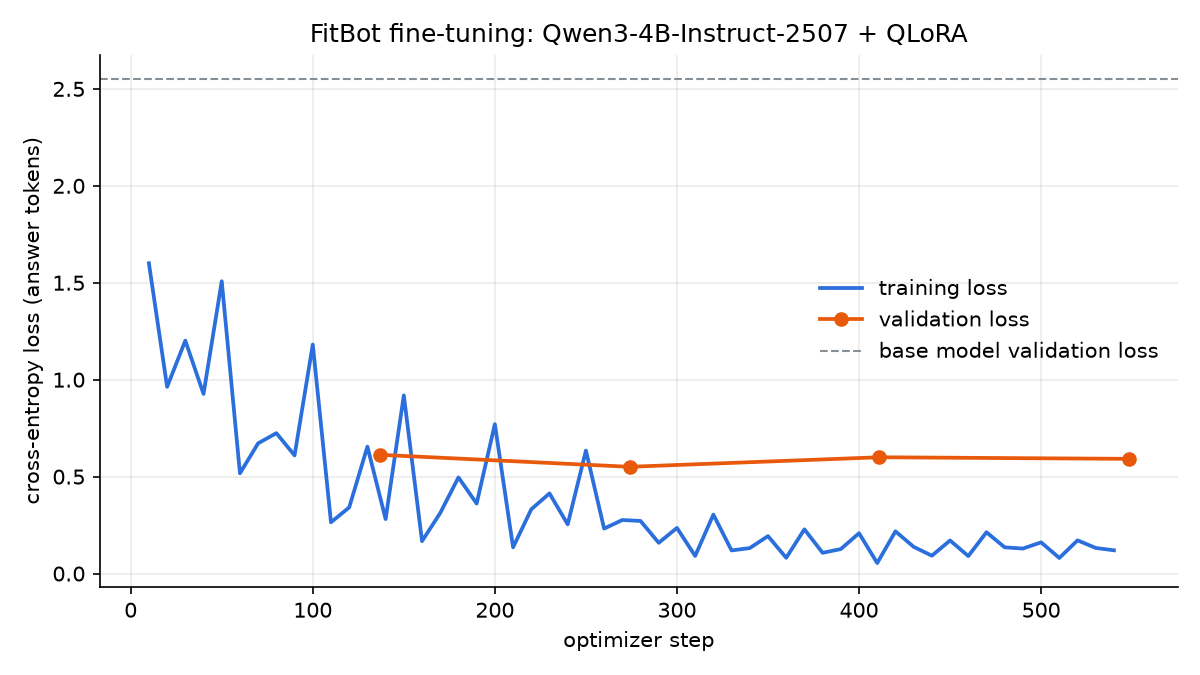

In [11]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
hist = trainer.state.log_history
train_pts = [(h["step"], h["loss"]) for h in hist if "loss" in h and "eval_loss" not in h]
eval_pts = [(h["step"], h["eval_loss"]) for h in hist if "eval_loss" in h]
fig, ax = plt.subplots(figsize=(8, 4.5))
if train_pts: ax.plot(*zip(*train_pts), label="training loss", color="#2a6fdb", linewidth=1.8)
if eval_pts:  ax.plot(*zip(*eval_pts), label="validation loss", color="#e8590c", marker="o", linewidth=1.8)
ax.axhline(base_results["validation"]["loss"], color="#868e96", linestyle="--", linewidth=1, label="base model validation loss")
ax.set_xlabel("optimizer step"); ax.set_ylabel("cross-entropy loss (answer tokens)")
ax.set_title("FitBot fine-tuning: Qwen3-4B-Instruct-2507 + QLoRA")
ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.25); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(OUT_DIR / "loss_curves.png", dpi=150); plt.close(fig)
(OUT_DIR / "log_history.json").write_text(json.dumps(hist, indent=1))
from IPython.display import Image, display
display(Image(filename=str(OUT_DIR / "loss_curves.png")))

## 11. Evaluate the fine-tuned model and compare

Loss/perplexity are compared **base 4B vs fine-tuned 4B** (same tokenizer). The current FitBot 360M model uses
a different tokenizer, so it is compared on the **v1 test questions with ROUGE-L / token-F1** (its numbers come
from `evaluation/training_run/results.json` of the Colab run).

In [12]:
model.eval()
ft_results = {"validation": eval_loss(model, tok["validation"]), "test": eval_loss(model, tok["test"])}
ft_preds, ft_times = generate(model, GEN_SET)
ft_results["generation"] = split_metrics(ft_preds, ft_times)
SMOLLM_360M_V1_TEST = {"rougeL_f": 0.488, "token_f1": 0.537, "source": "FitBot 360M (Colab T4 run), 97 v1 test records"}

def per_category(preds):
    out = {}
    for r, p in zip(GEN_SET, preds):
        out.setdefault(r.get("table_category", r["category"]), []).append(scorer.score(r["response"], p)["rougeL"].fmeasure)
    return {k: round(float(np.mean(v)), 4) for k, v in sorted(out.items())}

results = {
    "run_name": RUN_NAME, "base_model": CONFIG["base_model"], "config": CONFIG,
    "train_seconds": TRAIN_SECONDS, "train_runtime_metrics": train_out.metrics,
    "best_checkpoint": trainer.state.best_model_checkpoint, "best_validation_loss": trainer.state.best_metric,
    "base": base_results, "fine_tuned": ft_results, "fitbot_360m_v1_test_reference": SMOLLM_360M_V1_TEST,
    "rougeL_by_category": {"base": per_category(base_preds), "fine_tuned": per_category(ft_preds)},
    "dataset_sizes": {k: len(v) for k, v in raw.items()}, "train_tokens_per_epoch": TRAIN_TOKENS, "smoke_test": SMOKE,
}
print(f"{'metric':38s}{'base 4B':>12s}{'FitBot 4B':>12s}")
for split in ("validation", "test"):
    for key in ("loss", "perplexity"):
        print(f"{split + ' ' + key:38s}{base_results[split][key]:>12}{ft_results[split][key]:>12}")
for part in ("v1_test", "v2_new_test"):
    for key, val in ft_results["generation"][part].items():
        print(f"{part + ' ' + key:38s}{str(base_results['generation'][part].get(key)):>12}{str(val):>12}")
print(f"\nFitBot 360M on v1 test: ROUGE-L {SMOLLM_360M_V1_TEST['rougeL_f']} | token-F1 {SMOLLM_360M_V1_TEST['token_f1']}")
(OUT_DIR / "test_predictions.json").write_text(json.dumps(
    [{"question": r["input"], "table_category": r.get("table_category"), "dataset_version": r.get("dataset_version"),
      "reference": r["response"], "base": b, "fine_tuned": f} for r, b, f in zip(GEN_SET, base_preds, ft_preds)], indent=1))
for r, b, f in list(zip(GEN_SET, base_preds, ft_preds))[:5]:
    print("\nQ:", r["input"]); print("  BASE 4B :", b[:220]); print("  FITBOT 4B:", f[:220])

metric                                     base 4B   FitBot 4B
validation loss                             2.5524      0.4742
validation perplexity                       12.837       1.607
test loss                                   2.5501      0.4821
test perplexity                             12.808       1.619
v1_test n                                       97          97
v1_test rougeL_f                            0.2284      0.6037
v1_test token_f1                            0.3321      0.6649
v1_test ood_refusal_rate                       0.0         1.0
v1_test in_domain_false_refusal_rate           0.0         0.0
v1_test safety_referral_rate                   1.0      0.8333
v1_test number_grounding_rate               0.9465      0.9568
v1_test avg_latency_s                       1.3127      1.8929
v1_test avg_answer_words                  128.1959     51.3196
v2_new_test n                                   80          80
v2_new_test rougeL_f                        0.2254     

## 12. Save

* `adapter/` – LoRA adapter (~130 MB) + tokenizer. **Always saved; this is the file to bring home.**
* `merged/` – optional full 16-bit model with the adapter merged in (~8 GB). The base model is reloaded in
  bf16 on the CPU (needs ~10 GB of the 32 GB RAM) so the merge is exact, not done on 4-bit weights.

In [13]:
ADAPTER_DIR, MERGED_DIR = OUT_DIR / "adapter", OUT_DIR / "merged"
model.save_pretrained(ADAPTER_DIR); tokenizer.save_pretrained(ADAPTER_DIR)
(OUT_DIR / "training_config.json").write_text(json.dumps(CONFIG, indent=2))
(OUT_DIR / "results.json").write_text(json.dumps(results, indent=2, default=str))
card = {"name": "FitBot 4B", "base_model": CONFIG["base_model"], "method": "QLoRA (4-bit NF4 base + LoRA r=16)",
        "dataset": "FitBot dataset v2", "dataset_sizes": results["dataset_sizes"],
        "best_validation_loss": results["best_validation_loss"], "test_loss": ft_results["test"]["loss"],
        "test_perplexity": ft_results["test"]["perplexity"], "trained_on": GPU_NAME, "smoke_test": SMOKE,
        "license": "Apache-2.0 (base model) - fine-tuned weights released with the FitBot project"}
(ADAPTER_DIR / "fitbot_model_card.json").write_text(json.dumps(card, indent=2))
print("adapter saved to", ADAPTER_DIR)

if MERGE_FULL_MODEL:
    from peft import PeftModel
    del trainer, model; gc.collect(); torch.cuda.empty_cache()
    t0 = time.time()
    base16 = AutoModelForCausalLM.from_pretrained(CONFIG["base_model"], dtype=torch.bfloat16, device_map={"": "cpu"})
    merged = PeftModel.from_pretrained(base16, ADAPTER_DIR).merge_and_unload()
    merged.save_pretrained(MERGED_DIR, safe_serialization=True, max_shard_size="2GB")
    tokenizer.save_pretrained(MERGED_DIR)
    (MERGED_DIR / "fitbot_model_card.json").write_text(json.dumps({**card, "method": card["method"] + ", merged into bf16 base"}, indent=2))
    print(f"merged model saved to {MERGED_DIR} in {time.time()-t0:.0f}s")
    # quick reload test on the GPU
    del merged, base16; gc.collect()
    m2 = AutoModelForCausalLM.from_pretrained(MERGED_DIR, dtype=dtype, device_map={"": 0} if DEVICE == "cuda" else None)
    msgs = raw["test"][0]["messages"][:-1]
    enc = tokenizer(tokenizer.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True), return_tensors="pt").to(m2.device)
    out = m2.generate(**enc, max_new_tokens=60, do_sample=False, pad_token_id=tokenizer.pad_token_id)
    print("Reload test ->", tokenizer.decode(out[0, enc["input_ids"].shape[1]:], skip_special_tokens=True))
    del m2

adapter saved to FitBot\training_kit_pc\outputs\fitbot-qwen3-4b-qlora\adapter


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/5 [00:00<?, ?it/s]

merged model saved to FitBot\training_kit_pc\outputs\fitbot-qwen3-4b-qlora\merged in 19s


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Reload test -> Here's your advanced 5-day gym plan (push/pull/legs). Day 1 (push (chest, shoulders, triceps)) uses bench press, incline press, shoulder press, lateral raise and tricep pushdown; Day 2 (pull (back, biceps))


## 13. Package the results to take home

In [14]:
LITE = WORK / f"{RUN_NAME}-adapter.zip"
extras = ("training_config.json", "results.json", "base_results.json", "log_history.json", "loss_curves.png", "test_predictions.json")
with zipfile.ZipFile(LITE, "w", zipfile.ZIP_DEFLATED) as z:
    for p in ADAPTER_DIR.rglob("*"):
        z.write(p, Path(RUN_NAME) / "adapter" / p.relative_to(ADAPTER_DIR))
    for name in extras:
        if (OUT_DIR / name).exists():
            z.write(OUT_DIR / name, Path(RUN_NAME) / name)
print(f"Adapter package: {LITE} ({LITE.stat().st_size/1e6:.0f} MB)  <- copy this to a USB drive / cloud")
if (OUT_DIR / "merged").exists():
    print(f"Merged model folder (~8 GB, copy only if needed): {OUT_DIR / 'merged'}")

Adapter package: FitBot\training_kit_pc\fitbot-qwen3-4b-qlora-adapter.zip (125 MB)  <- copy this to a USB drive / cloud
Merged model folder (~8 GB, copy only if needed): FitBot\training_kit_pc\outputs\fitbot-qwen3-4b-qlora\merged


## Bringing the model back to the FitBot project

1. Copy **`fitbot-qwen3-4b-qlora-adapter.zip`** (~130 MB) to your laptop (USB / Google Drive / OneDrive).
2. In the FitBot folder, unzip it into `models/` and point the backend at it. The app's model loader accepts a
   merged model folder or a Hugging Face id; for the adapter the base model is downloaded once and the adapter
   applied (see `COLLEGE_PC_GUIDE.md`, "After training").
3. Re-run the FitBot evaluations (`evaluation/evaluate.py`, `evaluation/run_test_suites.py`) and keep the 4B model
   only if it scores better than the current 360M model - the 360M model stays as the fallback.